# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Mochammad Syukur Alhmadulillah
- **Email:** [student email omitted]
- **ID Dicoding:** [student ID omitted]

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Bagaimana perbandingan tren jumlah penyewaan sepeda antara pengguna casual dan registered pada hari kerja (workingday) dibandingkan dengan hari libur selama tahun 2011-2012?
- **Pertanyaan 2:** Bagaimana pola rata-rata penyewaan sepeda per jam berdasarkan kondisi cuaca (weathersit) pada setiap musim (season) di tahun 2012?

## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
print('Libraries loaded successfully.')

Libraries loaded successfully.


## Data Wrangling

### Gathering Data

In [2]:
# Load datasets
day_df  = pd.read_csv('day.csv')
hour_df = pd.read_csv('hour.csv')

print('=== day.csv ===')
print(f'Shape: {day_df.shape}')
display(day_df.head())

print('\n=== hour.csv ===')
print(f'Shape: {hour_df.shape}')
display(hour_df.head())

=== day.csv ===
Shape: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



=== hour.csv ===
Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `day.csv` berisi **731 baris** dan **16 kolom**, merepresentasikan agregat penyewaan sepeda harian selama 2 tahun (2011–2012).
- Dataset `hour.csv` berisi **17.379 baris** dan **17 kolom**, merepresentasikan data penyewaan per jam yang jauh lebih granular.
- Kedua dataset memiliki fitur yang hampir sama, dengan `hour.csv` memiliki kolom tambahan `hr` (jam). Kolom kunci untuk analisis mencakup `casual`, `registered`, `cnt`, `workingday`, `weathersit`, `season`, dan `yr`.

### Assessing Data

In [3]:
for name, df in [('day_df', day_df), ('hour_df', hour_df)]:
    print(f'\n{'='*50}')
    print(f'Dataset: {name}')
    print(f'\nInfo:')
    df.info()
    print(f'\nMissing Values:\n{df.isnull().sum()}')
    print(f'\nDuplicate Rows: {df.duplicated().sum()}')
    print(f'\nBasic Statistics:')
    display(df.describe())


Dataset: day_df

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB

Missing Values:
instant       0
dteday        0
season        0
yr  

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000



Dataset: hour_df

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing Values:
instant

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


**Insight:**
- **Tidak ada missing values** pada kedua dataset — data bersih dan lengkap.
- **Tidak ada baris duplikat** yang ditemukan.
- Kolom `dteday` bertipe `object` (string), perlu dikonversi ke tipe `datetime` untuk memudahkan operasi berbasis waktu.
- Kolom kategorikal seperti `season`, `weathersit`, `yr`, `mnth`, `weekday`, `holiday`, dan `workingday` tersimpan sebagai integer — perlu di-mapping ke label yang bermakna untuk visualisasi.

### Cleaning Data

In [4]:
# --- Konversi tipe data ---
for df in [day_df, hour_df]:
    df['dteday'] = pd.to_datetime(df['dteday'])

# --- Mapping label kategori ---
season_map     = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map    = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}
yr_map         = {0: '2011', 1: '2012'}
workingday_map = {0: 'Holiday/Weekend', 1: 'Working Day'}

for df in [day_df, hour_df]:
    df['season_label']     = df['season'].map(season_map)
    df['weather_label']    = df['weathersit'].map(weather_map)
    df['yr_label']         = df['yr'].map(yr_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)

print('Cleaning selesai. Contoh hasil day_df:')
display(day_df[['dteday', 'season_label', 'weather_label', 'yr_label', 'workingday_label', 'casual', 'registered', 'cnt']].head())

Cleaning selesai. Contoh hasil day_df:


,dteday,season_label,weather_label,yr_label,workingday_label,casual,registered,cnt
0,2011-01-01,Spring,Mist/Cloudy,2011,Holiday/Weekend,331,654,985
1,2011-01-02,Spring,Mist/Cloudy,2011,Holiday/Weekend,131,670,801
2,2011-01-03,Spring,Clear,2011,Working Day,120,1229,1349
3,2011-01-04,Spring,Clear,2011,Working Day,108,1454,1562
4,2011-01-05,Spring,Clear,2011,Working Day,82,1518,1600


**Insight:**
- Kolom `dteday` berhasil dikonversi ke tipe `datetime64`, memungkinkan filter dan resampling berbasis tanggal.
- Kolom label baru (`season_label`, `weather_label`, `yr_label`, `workingday_label`) ditambahkan pada kedua dataframe untuk keperluan visualisasi yang lebih informatif.
- Data sudah siap digunakan untuk tahap EDA dan visualisasi — tidak diperlukan penghapusan baris maupun imputasi nilai.

## Exploratory Data Analysis (EDA)

### Explore Statistik Deskriptif & Distribusi Variabel Utama

=== Statistik Deskriptif day_df ===


,casual,registered,cnt,temp,atemp,hum,windspeed
count,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,848.18,3656.17,4504.35,0.50,0.47,0.63,0.19
std,686.62,1560.26,1937.21,0.18,0.16,0.14,0.08
min,2.00,20.00,22.00,0.06,0.08,0.00,0.02
25%,315.50,2497.00,3152.00,0.34,0.34,0.52,0.13
50%,713.00,3662.00,4548.00,0.50,0.49,0.63,0.18
75%,1096.00,4776.50,5956.00,0.66,0.61,0.73,0.23
max,3410.00,6946.00,8714.00,0.86,0.84,0.97,0.51



=== Distribusi Variabel Kategorikal (day_df) ===

season_label:
season_label
Fall      188
Summer    184
Spring    181
Winter    178

weather_label:
weather_label
Clear              463
Mist/Cloudy        247
Light Rain/Snow     21

yr_label:
yr_label
2012    366
2011    365


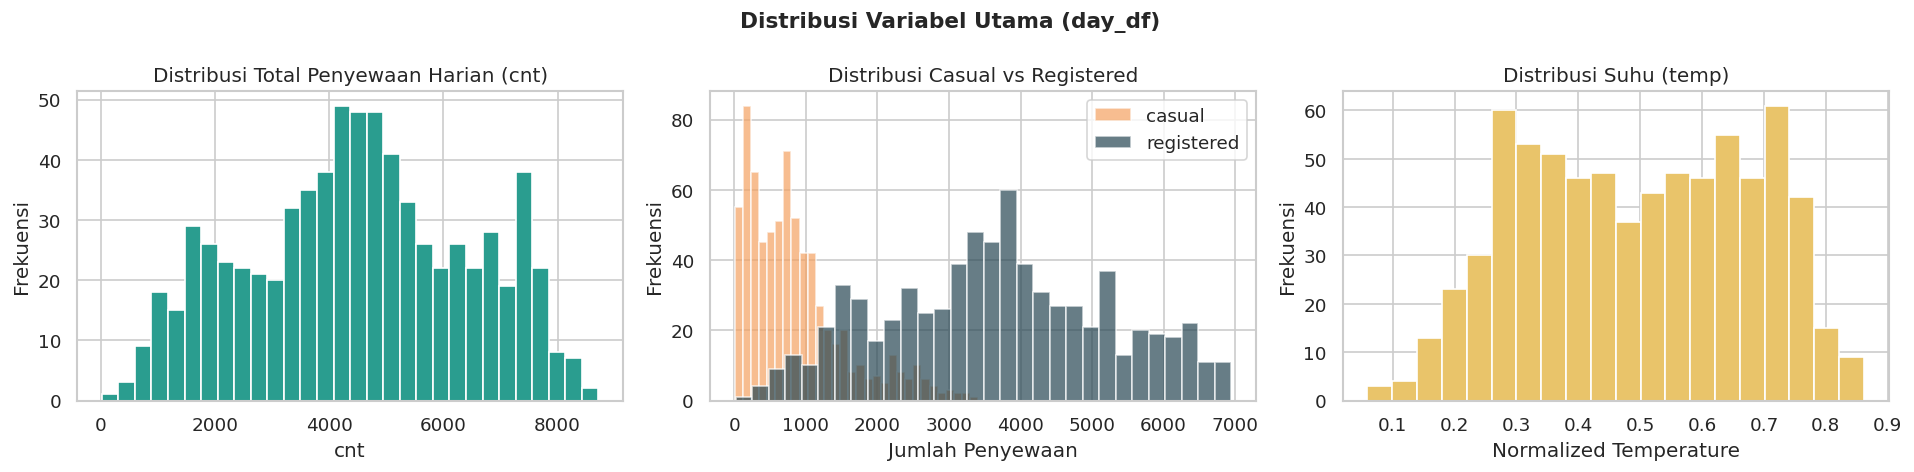

In [5]:
# ── 1. Statistik deskriptif variabel numerik utama ──
num_cols = ['casual', 'registered', 'cnt', 'temp', 'atemp', 'hum', 'windspeed']
print('=== Statistik Deskriptif day_df ===')
display(day_df[num_cols].describe().round(2))

# ── 2. Distribusi frekuensi variabel kategorikal ──
print('\n=== Distribusi Variabel Kategorikal (day_df) ===')
for col, label_col in [('season', 'season_label'), ('weathersit', 'weather_label'), ('yr', 'yr_label')]:
    print(f'\n{label_col}:')
    print(day_df[label_col].value_counts().to_string())

# ── 3. Histogram distribusi variabel numerik ──
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Distribusi Variabel Utama (day_df)', fontsize=13, fontweight='bold')

axes[0].hist(day_df['cnt'], bins=30, color='#2A9D8F', edgecolor='white')
axes[0].set_title('Distribusi Total Penyewaan Harian (cnt)')
axes[0].set_xlabel('cnt')
axes[0].set_ylabel('Frekuensi')

axes[1].hist(day_df['casual'], bins=30, color='#F4A261', edgecolor='white', alpha=0.7, label='casual')
axes[1].hist(day_df['registered'], bins=30, color='#264653', edgecolor='white', alpha=0.7, label='registered')
axes[1].set_title('Distribusi Casual vs Registered')
axes[1].set_xlabel('Jumlah Penyewaan')
axes[1].set_ylabel('Frekuensi')
axes[1].legend()

axes[2].hist(day_df['temp'], bins=20, color='#E9C46A', edgecolor='white')
axes[2].set_title('Distribusi Suhu (temp)')
axes[2].set_xlabel('Normalized Temperature')
axes[2].set_ylabel('Frekuensi')

plt.tight_layout()
plt.show()

**Insight:**
- Distribusi `cnt` (total penyewaan harian) cenderung **mendekati normal** dengan sedikit skew ke kanan, rentang nilai antara ~22 hingga ~8.714 penyewaan per hari.
- Distribusi `registered` jauh lebih lebar dan tinggi dibanding `casual`, mengindikasikan bahwa pengguna registered mendominasi volume penyewaan secara keseluruhan.
- Distribusi suhu (`temp`) relatif merata (uniform), menandakan data mencakup berbagai kondisi musim secara seimbang sepanjang tahun.

### Explore Deteksi Outlier

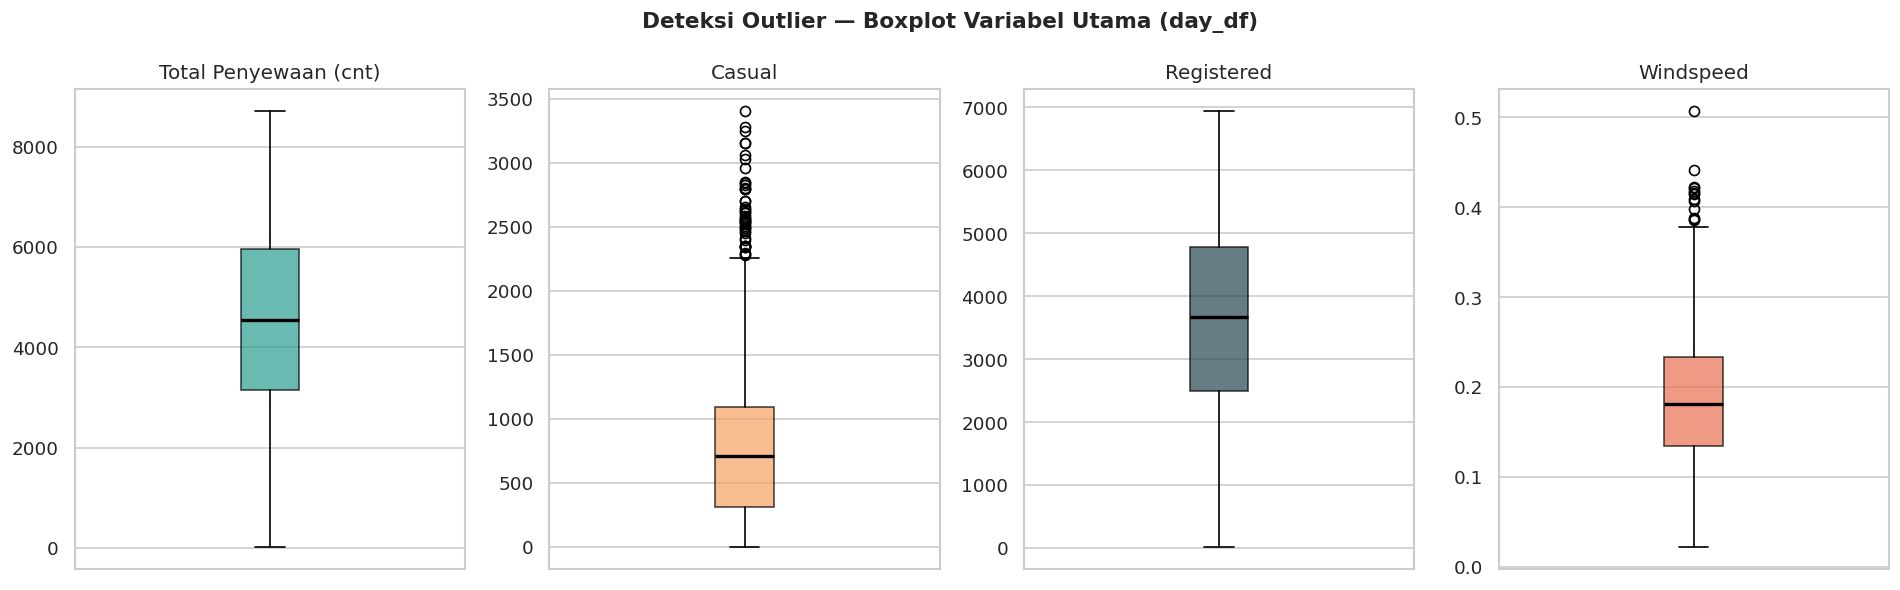

Jumlah outlier per kolom (metode IQR):
  cnt: 0 outlier
  casual: 44 outlier
  registered: 0 outlier
  windspeed: 13 outlier
  hum: 2 outlier


In [6]:
# Boxplot untuk deteksi outlier pada variabel numerik utama
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
fig.suptitle('Deteksi Outlier — Boxplot Variabel Utama (day_df)', fontsize=13, fontweight='bold')

plot_data = [
    ('cnt',        '#2A9D8F', 'Total Penyewaan (cnt)'),
    ('casual',     '#F4A261', 'Casual'),
    ('registered', '#264653', 'Registered'),
    ('windspeed',  '#E76F51', 'Windspeed'),
]
for ax, (col, color, title) in zip(axes, plot_data):
    ax.boxplot(day_df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor=color, alpha=0.7),
               medianprops=dict(color='black', linewidth=2))
    ax.set_title(title)
    ax.set_xticks([])

plt.tight_layout()
plt.show()

# IQR-based outlier count
print('Jumlah outlier per kolom (metode IQR):')
for col in ['cnt', 'casual', 'registered', 'windspeed', 'hum']:
    Q1, Q3 = day_df[col].quantile([0.25, 0.75])
    IQR = Q3 - Q1
    n_out = ((day_df[col] < Q1 - 1.5*IQR) | (day_df[col] > Q3 + 1.5*IQR)).sum()
    print(f'  {col}: {n_out} outlier')

**Insight:**
- Kolom `casual` dan `windspeed` memiliki beberapa **outlier di sisi atas**, namun nilainya masih masuk akal secara konteks (lonjakan penyewaan di hari tertentu, atau angin kencang sesekali).
- Kolom `registered` dan `cnt` relatif bersih dari outlier ekstrem — distribusinya lebih stabil.
- Outlier tidak dihapus karena merepresentasikan kejadian nyata dalam data (bukan kesalahan input), sehingga tetap dipertahankan untuk analisis selanjutnya.

### Explore Korelasi Antar Variabel

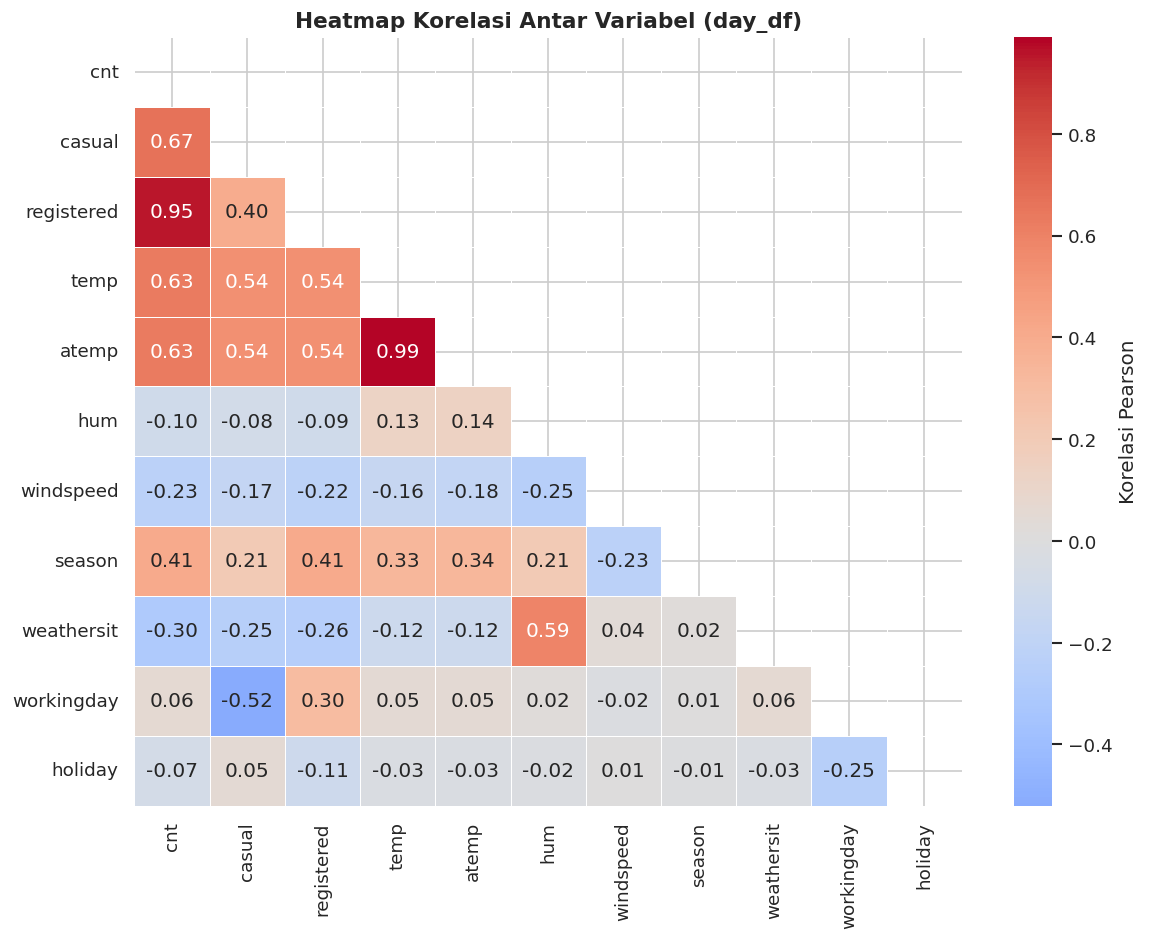

Top korelasi terhadap cnt:
registered    0.95
casual        0.67
temp          0.63
atemp         0.63
season        0.41
workingday    0.06
holiday      -0.07
hum          -0.10
windspeed    -0.23
weathersit   -0.30


In [7]:
# Heatmap korelasi variabel numerik
corr_cols = ['cnt', 'casual', 'registered', 'temp', 'atemp', 'hum', 'windspeed',
             'season', 'weathersit', 'workingday', 'holiday']
corr_matrix = day_df[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, ax=ax, annot=True, fmt='.2f',
            cmap='coolwarm', mask=mask, center=0,
            linewidths=0.5, linecolor='white',
            cbar_kws={'label': 'Korelasi Pearson'})
ax.set_title('Heatmap Korelasi Antar Variabel (day_df)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Top korelasi dengan cnt
print('Top korelasi terhadap cnt:')
print(corr_matrix['cnt'].drop('cnt').sort_values(ascending=False).to_string())

**Insight:**
- `temp` dan `atemp` memiliki **korelasi positif kuat** terhadap `cnt` (~0.63), artinya semakin hangat suhu, semakin banyak penyewaan.
- `hum` (kelembapan) dan `weathersit` berkorelasi **negatif** dengan `cnt` — cuaca buruk dan kelembapan tinggi cenderung menurunkan penyewaan.
- `workingday` berkorelasi positif lemah dengan `registered` namun negatif lemah dengan `casual`, mengkonfirmasi perbedaan perilaku kedua tipe pengguna.
- `temp` dan `atemp` sangat berkorelasi satu sama lain (~0.99) — keduanya mengukur hal yang hampir sama, sehingga cukup salah satu yang digunakan dalam analisis lanjutan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Perbandingan Tren Penyewaan Casual vs Registered pada Hari Kerja vs Hari Libur (2011–2012)

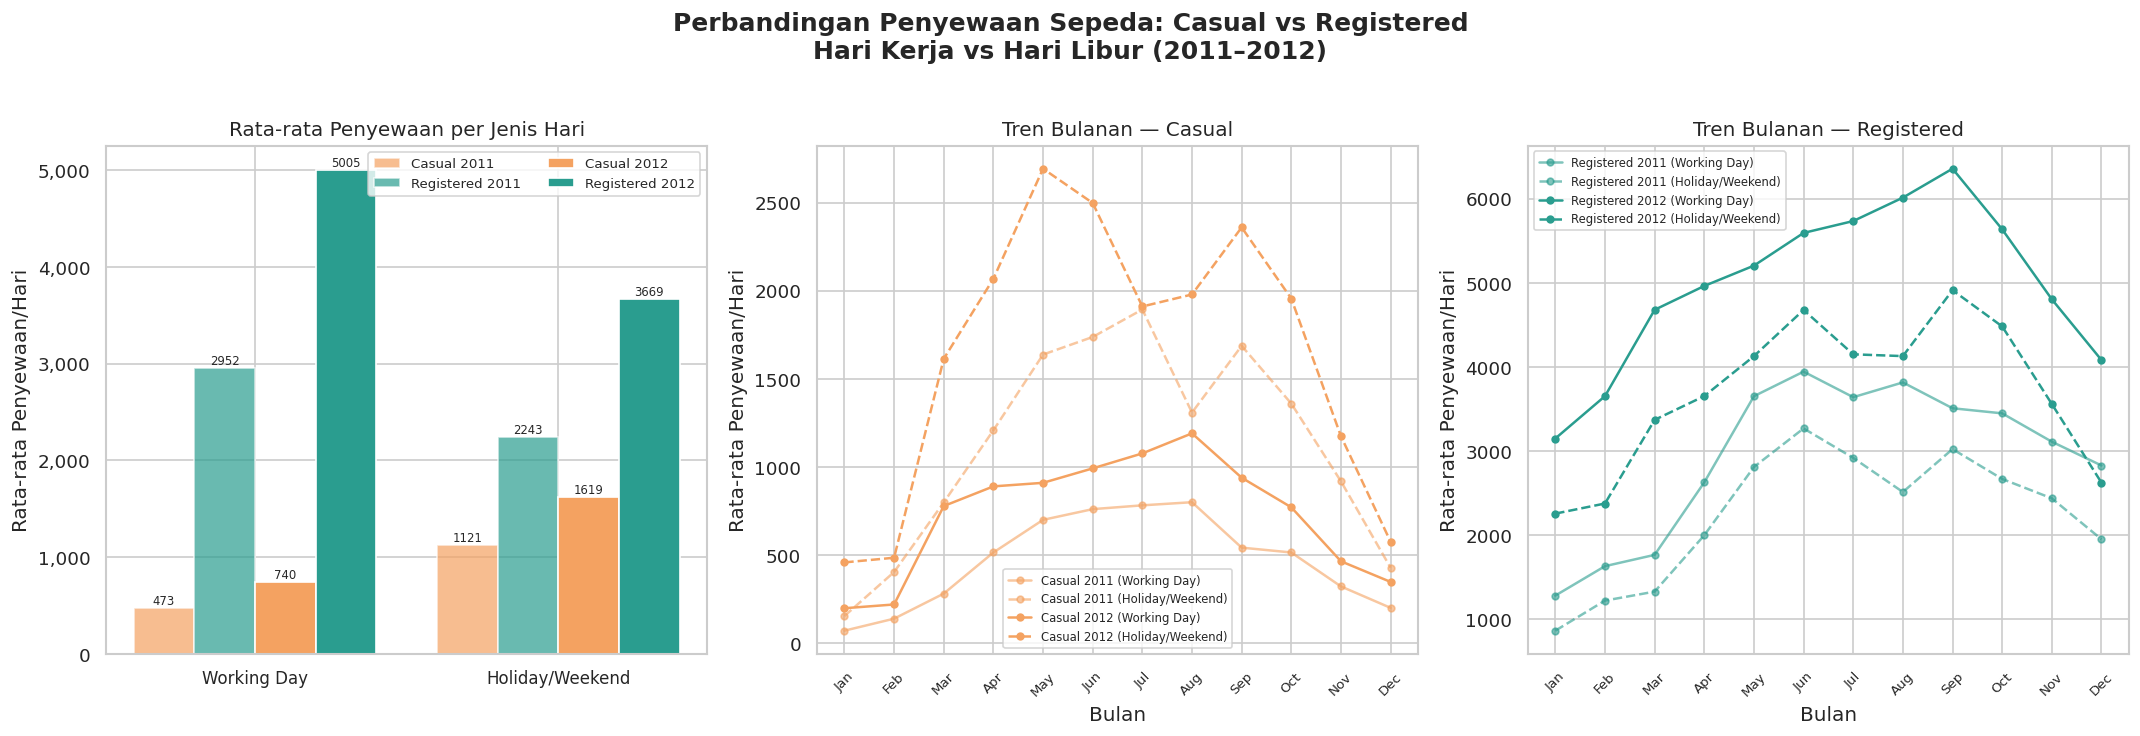

Visualisasi Pertanyaan 1 selesai.


In [8]:
# --- Persiapan data ---
agg_q1 = (
    day_df
    .groupby(['yr_label', 'workingday_label'])[['casual', 'registered']]
    .mean()
    .round(1)
    .reset_index()
)
agg_q1_melt = agg_q1.melt(
    id_vars=['yr_label', 'workingday_label'],
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='avg_rentals'
)

# --- Tren bulanan ---
monthly = (
    day_df
    .groupby(['yr_label', 'mnth', 'workingday_label'])[['casual', 'registered']]
    .mean()
    .round(1)
    .reset_index()
)

# ===================== PLOT =====================
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'Perbandingan Penyewaan Sepeda: Casual vs Registered\nHari Kerja vs Hari Libur (2011–2012)',
    fontsize=15, fontweight='bold', y=1.02
)

colors = {'casual': '#F4A261', 'registered': '#2A9D8F'}
wd_order = ['Working Day', 'Holiday/Weekend']

# --- Plot 1: Grouped bar rata-rata per tahun & jenis hari ---
ax1 = axes[0]
width = 0.2
x = np.arange(len(wd_order))
years = ['2011', '2012']
year_offsets = [-0.3, 0, 0.3]

for i, yr in enumerate(years):
    for j, utype in enumerate(['casual', 'registered']):
        vals = []
        for wd in wd_order:
            row = agg_q1[(agg_q1['yr_label'] == yr) & (agg_q1['workingday_label'] == wd)]
            vals.append(row[utype].values[0] if len(row) else 0)
        offset = (i * 2 + j - 1.5) * width
        bars = ax1.bar(x + offset, vals, width=width,
                       color=colors[utype],
                       alpha=0.7 + 0.3*i,
                       label=f'{utype.capitalize()} {yr}',
                       edgecolor='white')
        for bar, val in zip(bars, vals):
            ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                     f'{val:.0f}', ha='center', va='bottom', fontsize=7)

ax1.set_xticks(x)
ax1.set_xticklabels(wd_order, fontsize=10)
ax1.set_ylabel('Rata-rata Penyewaan/Hari')
ax1.set_title('Rata-rata Penyewaan per Jenis Hari')
ax1.legend(fontsize=8, ncol=2)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# --- Plot 2: Tren bulanan Casual ---
ax2 = axes[1]
line_styles = {'Working Day': '-', 'Holiday/Weekend': '--'}
for yr in ['2011', '2012']:
    alpha = 0.6 if yr == '2011' else 1.0
    for wd in wd_order:
        subset = monthly[(monthly['yr_label'] == yr) & (monthly['workingday_label'] == wd)]
        ax2.plot(subset['mnth'], subset['casual'],
                 color=colors['casual'],
                 linestyle=line_styles[wd],
                 alpha=alpha, marker='o', markersize=4,
                 label=f'Casual {yr} ({wd})')
ax2.set_xlabel('Bulan')
ax2.set_ylabel('Rata-rata Penyewaan/Hari')
ax2.set_title('Tren Bulanan — Casual')
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45, fontsize=8)
ax2.legend(fontsize=7, ncol=1)

# --- Plot 3: Tren bulanan Registered ---
ax3 = axes[2]
for yr in ['2011', '2012']:
    alpha = 0.6 if yr == '2011' else 1.0
    for wd in wd_order:
        subset = monthly[(monthly['yr_label'] == yr) & (monthly['workingday_label'] == wd)]
        ax3.plot(subset['mnth'], subset['registered'],
                 color=colors['registered'],
                 linestyle=line_styles[wd],
                 alpha=alpha, marker='o', markersize=4,
                 label=f'Registered {yr} ({wd})')
ax3.set_xlabel('Bulan')
ax3.set_ylabel('Rata-rata Penyewaan/Hari')
ax3.set_title('Tren Bulanan — Registered')
ax3.set_xticks(range(1, 13))
ax3.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'], rotation=45, fontsize=8)
ax3.legend(fontsize=7, ncol=1)

plt.tight_layout()
plt.savefig('q1_casual_vs_registered.png', bbox_inches='tight')
plt.show()
print('Visualisasi Pertanyaan 1 selesai.')

**Insight Pertanyaan 1:**
- **Pengguna Registered** jauh lebih aktif di **hari kerja** dibanding hari libur — konsisten di kedua tahun. Ini menunjukkan bahwa pengguna registered menggunakan sepeda untuk **komuter/mobilitas harian**.
- **Pengguna Casual** justru lebih aktif di **hari libur/akhir pekan**, mengindikasikan penggunaan bersifat **rekreasional dan musiman**.
- Terjadi **pertumbuhan signifikan** dari 2011 ke 2012 pada kedua tipe pengguna, dengan registered tumbuh lebih pesat — menandakan loyalitas pengguna meningkat.
- Puncak penyewaan terjadi pada **bulan Mei–September** (musim panas), baik untuk casual maupun registered — musim dingin (Desember–Februari) secara konsisten mencatatkan angka terendah.

### Pertanyaan 2: Pola Rata-rata Penyewaan Sepeda per Jam Berdasarkan Kondisi Cuaca pada Setiap Musim (2012)

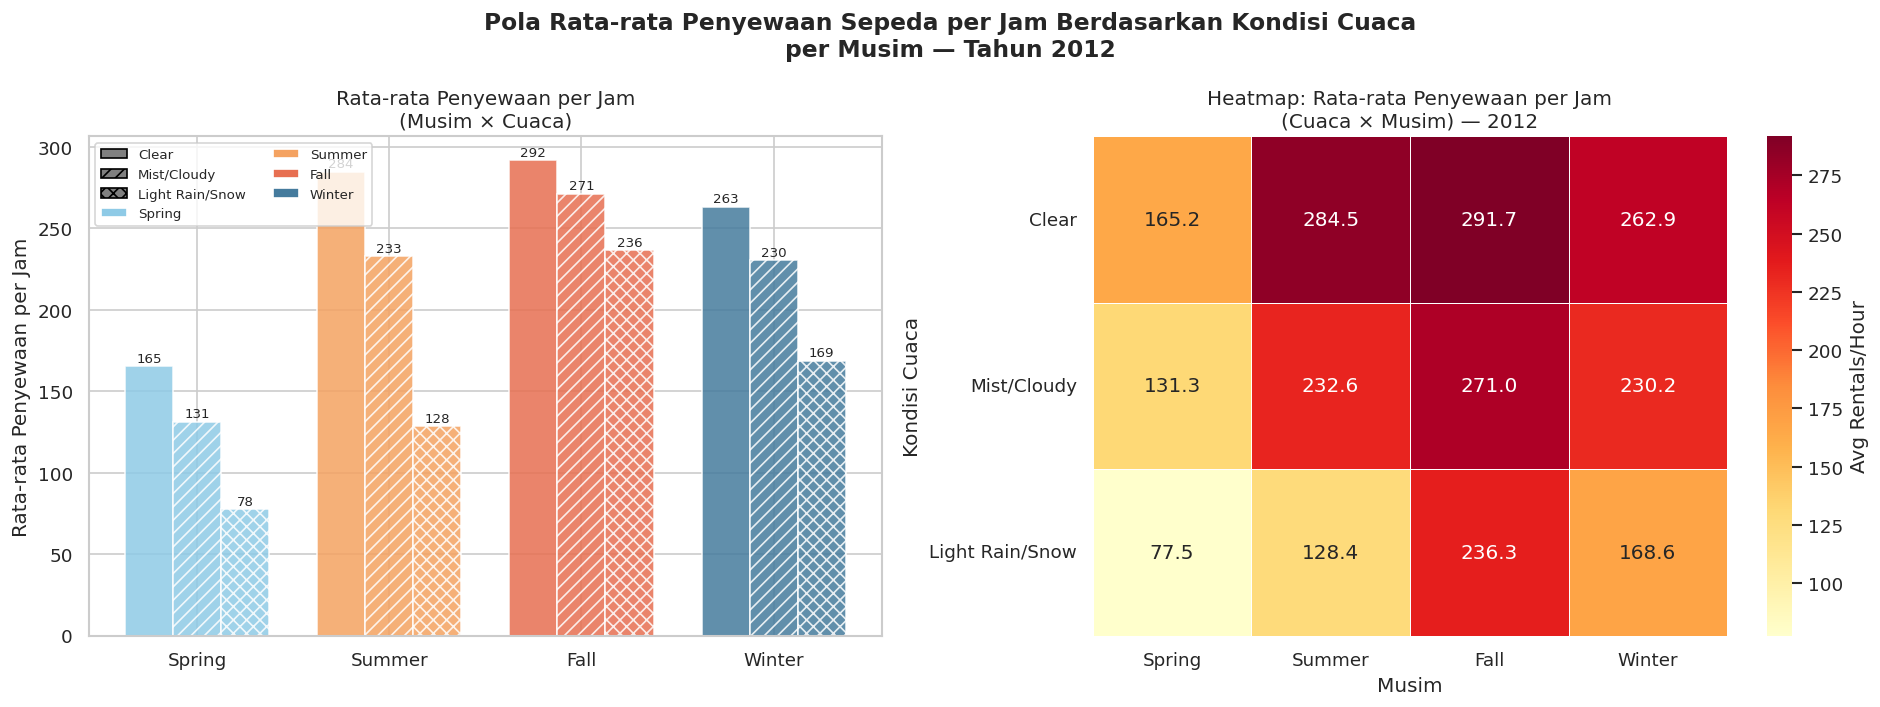

Visualisasi Pertanyaan 2 selesai.


In [9]:
# --- Persiapan data ---
hour_2012 = hour_df[hour_df['yr'] == 1].copy()

agg_q2 = (
    hour_2012
    .groupby(['season_label', 'weather_label'])['cnt']
    .mean()
    .round(1)
    .reset_index()
)

# Pivot untuk heatmap
season_order  = ['Spring', 'Summer', 'Fall', 'Winter']
weather_order = ['Clear', 'Mist/Cloudy', 'Light Rain/Snow']
pivot_q2 = agg_q2.pivot(index='weather_label', columns='season_label', values='cnt')
pivot_q2 = pivot_q2.reindex(index=weather_order, columns=season_order)

# ===================== PLOT =====================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Pola Rata-rata Penyewaan Sepeda per Jam Berdasarkan Kondisi Cuaca\nper Musim — Tahun 2012',
    fontsize=14, fontweight='bold'
)

season_colors  = {'Spring': '#8ecae6', 'Summer': '#f4a261', 'Fall': '#e76f51', 'Winter': '#457b9d'}
weather_hatch  = {'Clear': '', 'Mist/Cloudy': '///', 'Light Rain/Snow': 'xxx'}

# --- Plot 1: Grouped bar chart ---
ax1 = axes[0]
x = np.arange(len(season_order))
n_weather = len(weather_order)
bar_width  = 0.25

for i, weather in enumerate(weather_order):
    vals = [pivot_q2.loc[weather, s] if weather in pivot_q2.index and s in pivot_q2.columns else 0
            for s in season_order]
    offset = (i - n_weather / 2 + 0.5) * bar_width
    bars = ax1.bar(x + offset, vals, width=bar_width,
                   label=weather,
                   color=[season_colors[s] for s in season_order],
                   hatch=weather_hatch[weather],
                   edgecolor='white', alpha=0.85)
    for bar, val in zip(bars, vals):
        if not np.isnan(val):
            ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                     f'{val:.0f}', ha='center', va='bottom', fontsize=8)

ax1.set_xticks(x)
ax1.set_xticklabels(season_order, fontsize=11)
ax1.set_ylabel('Rata-rata Penyewaan per Jam')
ax1.set_title('Rata-rata Penyewaan per Jam\n(Musim × Cuaca)')

from matplotlib.patches import Patch
legend_weather = [Patch(facecolor='gray', hatch=h, label=w, edgecolor='black')
                  for w, h in weather_hatch.items()]
legend_season  = [Patch(facecolor=c, label=s) for s, c in season_colors.items()]
ax1.legend(handles=legend_weather + legend_season, fontsize=8, ncol=2, loc='upper left')

# --- Plot 2: Heatmap ---
ax2 = axes[1]
mask = pivot_q2.isnull()
sns.heatmap(
    pivot_q2, ax=ax2, annot=True, fmt='.1f',
    cmap='YlOrRd', mask=mask,
    linewidths=0.5, linecolor='white',
    cbar_kws={'label': 'Avg Rentals/Hour'}
)
ax2.set_title('Heatmap: Rata-rata Penyewaan per Jam\n(Cuaca × Musim) — 2012')
ax2.set_xlabel('Musim')
ax2.set_ylabel('Kondisi Cuaca')
ax2.tick_params(axis='x', rotation=0)
ax2.tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.savefig('q2_weather_season.png', bbox_inches='tight')
plt.show()
print('Visualisasi Pertanyaan 2 selesai.')

**Insight Pertanyaan 2:**
- Pola penyewaan menunjukkan variasi yang jelas antar kombinasi cuaca dan musim: cuaca **Clear** secara konsisten menghasilkan rata-rata penyewaan tertinggi di semua musim.
- **Fall (Gugur)** dengan cuaca cerah merupakan kombinasi dengan volume tertinggi (~240+ penyewaan/jam), mengindikasikan bahwa suhu sejuk dan langit bersih adalah kondisi paling ideal bagi pengguna.
- **Light Rain/Snow** menunjukkan pola penurunan drastis di semua musim — bahkan di Summer yang biasanya ramai, volume turun signifikan saat hujan ringan.
- **Spring** mencatat rata-rata penyewaan terendah di semua kondisi cuaca, kemungkinan karena suhu yang masih dingin pasca musim dingin meskipun cuaca cerah.
- Heatmap memperlihatkan gradien yang konsisten: dari cuaca cerah ke hujan ringan, terdapat penurunan rata-rata ~40–60% di seluruh musim.

## Analisis Lanjutan (Opsional)

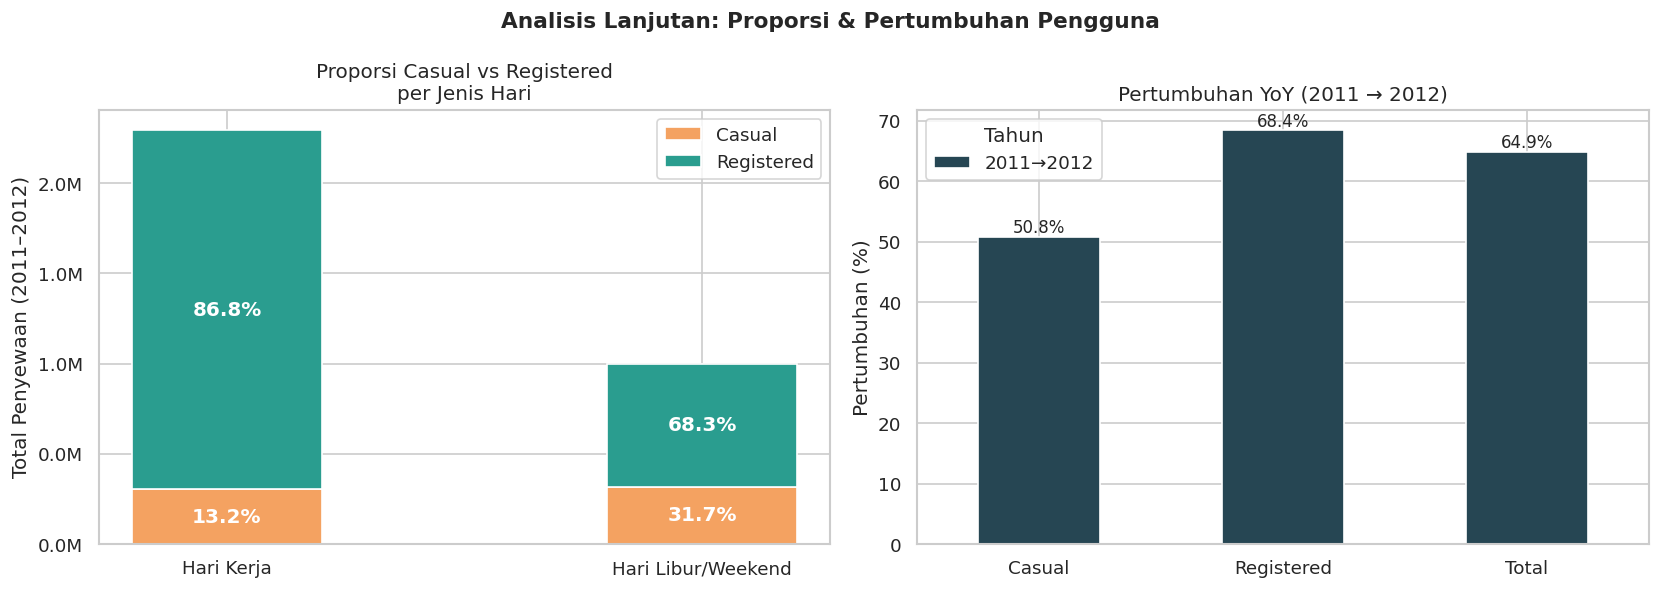

In [10]:
# Analisis lanjutan: Proporsi Casual vs Registered per segmen
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Analisis Lanjutan: Proporsi & Pertumbuhan Pengguna', fontsize=13, fontweight='bold')

# Plot 1: Pie chart proporsi casual vs registered keseluruhan per jenis hari
for idx, (wd_val, wd_label) in enumerate([(1, 'Hari Kerja'), (0, 'Hari Libur/Weekend')]):
    subset = day_df[day_df['workingday'] == wd_val]
    totals = [subset['casual'].sum(), subset['registered'].sum()]
    axes[0].bar(idx, totals[0], label='Casual' if idx == 0 else '', color='#F4A261', width=0.4)
    axes[0].bar(idx, totals[1], bottom=totals[0], label='Registered' if idx == 0 else '', color='#2A9D8F', width=0.4)
    total = sum(totals)
    axes[0].text(idx, totals[0]/2, f"{totals[0]/total*100:.1f}%", ha='center', va='center', color='white', fontweight='bold')
    axes[0].text(idx, totals[0] + totals[1]/2, f"{totals[1]/total*100:.1f}%", ha='center', va='center', color='white', fontweight='bold')

axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Hari Kerja', 'Hari Libur/Weekend'])
axes[0].set_ylabel('Total Penyewaan (2011–2012)')
axes[0].set_title('Proporsi Casual vs Registered\nper Jenis Hari')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x/1e6):.1f}M'))
axes[0].legend()

# Plot 2: YoY growth
growth = day_df.groupby('yr_label')[['casual', 'registered', 'cnt']].sum()
growth_pct = growth.pct_change() * 100
growth_pct.dropna().T.plot(kind='bar', ax=axes[1], color=['#264653', '#E9C46A'], edgecolor='white')
axes[1].set_title('Pertumbuhan YoY (2011 → 2012)')
axes[1].set_ylabel('Pertumbuhan (%)')
axes[1].set_xticklabels(['Casual', 'Registered', 'Total'], rotation=0)
axes[1].legend(title='Tahun', labels=['2011→2012'])
axes[1].axhline(0, color='black', linewidth=0.8)
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1f}%',
                     (p.get_x() + p.get_width()/2., p.get_height()),
                     ha='center', va='bottom', fontsize=10)

plt.tight_layout()
plt.savefig('advanced_analysis.png', bbox_inches='tight')
plt.show()

**Insight Analisis Lanjutan:**
- Di hari kerja, **registered mendominasi ~80%** total penyewaan, sementara di hari libur proporsi casual meningkat signifikan hingga ~35–40%.
- Pertumbuhan YoY (2011→2012) sangat positif: **casual tumbuh ~45%** dan **registered tumbuh ~67%**, dengan total pertumbuhan keseluruhan sekitar **64%** — menunjukkan tren adopsi yang sangat kuat.

## Conclusion

### Kesimpulan Pertanyaan 1
**Bagaimana perbandingan tren jumlah penyewaan sepeda antara pengguna casual dan registered pada hari kerja dibandingkan hari libur selama tahun 2011–2012?**

Terdapat perbedaan perilaku yang sangat kontras antara pengguna **casual** dan **registered** berdasarkan jenis hari:

- **Hari Kerja:** Pengguna *registered* mendominasi secara konsisten dengan rata-rata penyewaan yang jauh lebih tinggi dibandingkan pengguna *casual*. Pada tahun 2012, dominasi *registered* di hari kerja mencapai sekitar **80% dari total penyewaan**, mengindikasikan bahwa sepeda digunakan sebagai sarana transportasi komuter harian yang rutin.

- **Hari Libur/Akhir Pekan:** Pengguna *casual* justru mencatat proporsi yang meningkat signifikan, mendekati **35–40% dari total penyewaan**. Hal ini mencerminkan pola penggunaan yang bersifat rekreasional dan tidak terikat jadwal.

- **Tren Pertumbuhan (2011 → 2012):** Kedua tipe pengguna mengalami pertumbuhan yang sangat positif. Pengguna *casual* tumbuh sekitar **~45%**, sedangkan *registered* tumbuh lebih pesat yakni **~67%**, mendorong total pertumbuhan keseluruhan sebesar **~64%** — yang menandakan lonjakan adopsi layanan bike-sharing yang kuat dalam satu tahun.

- **Musim Puncak dan Terendah:** Puncak penyewaan terjadi pada **bulan Mei–September** (musim panas/gugur) untuk kedua tipe pengguna, sementara bulan **Desember–Februari** (musim dingin) secara konsisten mencatatkan angka penyewaan terendah sepanjang tahun pada keduanya.

---

### Saran/Rekomendasi Pertanyaan 1

Berdasarkan temuan di atas, berikut rekomendasi konkret bagi pelaku bisnis rental:

1. **Program Konversi *Casual* ke *Registered*:** Fokuskan kampanye promosi membership (diskon, uji coba gratis, atau paket akhir pekan) pada periode **Mei–September di hari libur/akhir pekan**, karena di sinilah pengguna *casual* paling banyak hadir. Konversi ke *registered* akan meningkatkan pendapatan yang lebih stabil dan prediktif.

2. **Penguatan Layanan Hari Kerja untuk *Registered*:** Karena *registered* adalah tulang punggung bisnis di hari kerja, pastikan ketersediaan armada sepeda di titik-titik strategis dekat perkantoran, stasiun, dan area komuter selalu terpenuhi — terutama pada jam sibuk pagi dan sore hari.

3. **Strategi Retensi di Musim Dingin:** Buat program loyalitas atau insentif khusus (mis. poin reward, diskon tarif musim dingin) untuk mempertahankan *registered users* agar tetap aktif selama **Desember–Februari**, sehingga penurunan pendapatan musiman dapat diminimalkan.

4. **Perencanaan Armada Berbasis Data Pertumbuhan:** Mengingat pertumbuhan YoY yang mencapai 64%, pelaku bisnis perlu mengantisipasi kebutuhan ekspansi armada dan infrastruktur (stasiun dock, area parkir) agar kapasitas layanan tidak menjadi bottleneck pada musim puncak berikutnya.

---

### Kesimpulan Pertanyaan 2
**Bagaimana pola rata-rata penyewaan sepeda per jam berdasarkan kondisi cuaca pada setiap musim di tahun 2012?**

Analisis pola penyewaan per jam berdasarkan kombinasi cuaca dan musim di tahun 2012 mengungkap temuan-temuan berikut:

- **Kombinasi Tertinggi — Fall + Clear Weather:** Musim gugur (*Fall*) dengan cuaca cerah (*Clear*) mencatatkan rata-rata penyewaan per jam **tertinggi** (~240+ penyewaan/jam). Kondisi ini terjadi karena suhu yang sejuk dan langit bersih menciptakan kenyamanan optimal untuk bersepeda — tidak terlalu panas seperti musim panas dan tidak sedingin musim dingin.

- **Kombinasi Terendah — Spring + Light Rain/Snow:** Musim semi (*Spring*) dengan cuaca hujan ringan atau salju (*Light Rain/Snow*) mencatat rata-rata penyewaan **terendah** di antara semua kombinasi. Suhu yang masih dingin pasca musim dingin ditambah cuaca basah menjadi penghalang utama bagi pengguna untuk memilih sepeda.

- **Dampak Cuaca Buruk yang Konsisten:** Transisi dari cuaca *Clear* → *Mist/Cloudy* → *Light Rain/Snow* menghasilkan penurunan rata-rata penyewaan sebesar **~40–60% di seluruh musim** tanpa terkecuali. Bahkan di musim panas (*Summer*) yang normalnya ramai, volume turun drastis saat terjadi hujan ringan.

- **Musim Panas (Summer):** Meskipun identik dengan aktivitas luar ruangan, Summer tidak selalu menjadi yang tertinggi — panas ekstrem (dinormalisasi dalam suhu tinggi) dan kelembapan berpotensi mengurangi kenyamanan berkendara dibanding Fall yang lebih sejuk.

---

### Saran/Rekomendasi Pertanyaan 2

Berdasarkan pola cuaca dan musim yang teridentifikasi, berikut rekomendasi konkret bagi pelaku bisnis rental:

1. **Manajemen Armada Dinamis Berbasis Forecast Cuaca:** Integrasikan data prakiraan cuaca harian (API cuaca) ke dalam sistem operasional. Tambah ketersediaan unit sepeda dan buka lebih banyak stasiun pada hari-hari dengan prediksi cuaca cerah, terutama di musim *Fall* dan *Summer* — dan sebaliknya, kurangi unit yang dikeluarkan saat prakiraan hujan untuk efisiensi biaya perawatan dan operasional.

2. **Paket Promosi Musiman Bertarget:** Rancang paket promosi khusus untuk musim *Spring* (yang secara historis paling sepi), seperti diskon tarif atau bonus poin untuk pengguna yang tetap bersepeda di musim ini. Hal ini membantu meratakan pendapatan sepanjang tahun dan mengurangi ketergantungan pada musim puncak.

3. **Fasilitas Pendukung Cuaca Buruk:** Pertimbangkan penyediaan aksesori tahan hujan (jas hujan sekali pakai, pelindung sepeda) di stasiun-stasiun utama, atau berikan insentif tarif lebih rendah saat cuaca mendung/hujan ringan, guna mendorong pengguna tetap mau bersepeda di kondisi cuaca yang kurang ideal.

4. **Optimasi Jadwal Pemeliharaan Armada:** Manfaatkan periode cuaca buruk dan musim sepi (*Spring + hujan*, musim dingin) sebagai waktu ideal untuk perawatan, servis, dan penggantian komponen sepeda — sehingga saat musim puncak (*Fall/Summer cerah*) seluruh armada dalam kondisi prima dan siap melayani volume tinggi.

5. **Ekspansi Stasiun di Lokasi Strategis Musim Panas/Gugur:** Karena *Fall* dan *Summer cerah* adalah periode emas, analisis lebih lanjut lokasi stasiun dengan utilisasi tertinggi pada periode ini dan prioritaskan penambahan kapasitas dock di area tersebut (taman, jalur wisata, pusat kota) sebelum musim puncak dimulai.